# Entrenar sin etiquetas

**Pregunta:** ¿Cómo puede una red aprender hologramas sin hologramas de ejemplo, y lo que aprendió se sostiene en volúmenes que nunca vio?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebook 01 de este tema (qué recibe y qué devuelve la red) y notebook 01 del tema 03-gerchberg-saxton (el lazo sobre trampas)
- **Tiempo de lectura:** unos 50 minutos; el notebook se ejecuta en unos 40 segundos

## Objetivos

El aprendizaje supervisado necesita pares: una entrada y la respuesta que la red debió dar. Para un holograma no hay tal respuesta que juntar, porque la mejor máscara de fase para un objetivo es justamente lo que cuesta calcular, y muchas máscaras hacen casi la misma luz. La red publicada evita el problema. Se entrena con una pérdida que solo necesita el objetivo: pregunta a la óptica, a través del modelo directo, qué luz hace la máscara de la propia red, y puntúa esa luz contra el objetivo. Calculará esa pérdida a mano sobre volúmenes nuevos, verá que separa una máscara informada de una no informada y que sube con suavidad alrededor de la fase de la red, verá lo que no mide, leerá el registro de entrenamiento y la evidencia con datos reservados que el producto guardó, y comprobará que el archivo bajo prueba es el que el registro describe. Terminará pudiendo decir qué respalda el registro con datos reservados y qué no.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.31.1
```

DinHot no publica un paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La red es el grafo ONNX publicado del producto, leído con onnxruntime. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, y luego los módulos del pipeline por su ruta
import hashlib
import importlib.metadata as md
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.holo.core import forward, metrics, modes
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.learned import convert, evaluation, generators
from pipeline.model.holo.methods.baseline import m04_gs
from pipeline.model.holo.methods.learned import m17_cgh_net

for name in ("numpy", "matplotlib", "onnxruntime"):
    print(name, md.version(name))


def unit_sum(image):
    """Una imagen de intensidad escalada para sumar uno."""
    return image / image.sum()


def overlap(goal, got):
    """La superposición 2 sum(T I) / (sum T^2 + sum I^2) de dos imágenes de suma uno, el AC de un plano."""
    return 2 * np.sum(goal * got) / (np.sum(goal**2) + np.sum(got**2))

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.31.1


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: sintética. Los volúmenes los sortea el generador con semilla del producto, la misma familia con que se entrenó la red, y no interviene ningún conjunto de datos de terceros; la licencia del repositorio cubre todos los archivos.
- Archivos leídos: `models/cgh-net.onnx` y su ficha `models/cgh-net.json`, el registro de entrenamiento `data/derived/models/cgh-net-training.json` y el detalle con datos reservados `data/derived/models/evaluation-detail.json`. Los dos últimos son la evidencia guardada del producto, leída aquí como evidencia y nunca usada para calcular las lecciones de la primera mitad.

La celda siguiente lee los cuatro archivos, abre el grafo y fija la geometría de la evaluación (un modulador espacial de luz (SLM) de 128 por 128 sin relleno, las tres profundidades del entrenamiento) a partir del módulo de evaluación del producto.

In [2]:
# el grafo publicado, su ficha, el registro de entrenamiento y el detalle con datos reservados, leídos como evidencia
models_dir = ROOT / "data" / "derived" / "models"
card = json.loads((ROOT / "models" / "cgh-net.json").read_text(encoding="utf-8"))
training = json.loads((models_dir / "cgh-net-training.json").read_text(encoding="utf-8"))
detail = json.loads((models_dir / "evaluation-detail.json").read_text(encoding="utf-8"))["cgh-net"]
session = ort.InferenceSession(str(ROOT / "models" / "cgh-net.onnx"), providers=["CPUExecutionProvider"])
setup, DEPTHS = evaluation.SETUP128, (-8, 0, 8)
zr = convert.rayleigh_range_m(setup)
print("volúmenes reservados en el detalle:", len(detail["rows"]))
print("claves del registro de entrenamiento:", ", ".join(sorted(training)))

volúmenes reservados en el detalle: 162
claves del registro de entrenamiento: config, heldout_sha256, onnx_bytes, operators, opset, parity_intensity_rel_max, parity_wrapped_abs_diff, slot, steps


## Método

**La pérdida.** Con $T_p$ la imagen objetivo en el plano $p$ e $I_p(\phi)$ la intensidad que la máscara de fase $\phi$ hace allí, ambas con suma unitaria, la red se entrena para minimizar $L(\phi) = 1 - \frac{1}{3}\sum_p 2\sum T_p I_p / (\sum T_p^2 + \sum I_p^2)$, la medida de exactitud de DeepCGH (Eybposh et al. 2020, https://doi.org/10.1364/OE.399624) tal como la lee el producto. La imagen de plano es $I_p = |\mathcal{F}\{A\,e^{i(\phi - \phi_{z_p})}\}|^2$ con $\phi_{z_p}$ el término de lente de la profundidad $z_p$. Nada en $L$ es un holograma guardado: un ejemplo de entrenamiento es un objetivo, y la "respuesta" se calcula a partir de la propia salida de la red. Cada paso de la cadena es diferenciable, de modo que el gradiente de $L$ llega a los pesos; la etapa de entrenamiento del producto lo hizo con una biblioteca de aprendizaje profundo que este entorno de notebooks no incluye, así que aquí el entrenamiento se lee de su registro y no se ejecuta.

**Lo que una pérdida sin etiquetas puede y no puede pedir.** Puede pedir luz que se traslape con las imágenes objetivo. No puede pedir nada que la pérdida no contenga: la intensidad de cada trampa, la potencia en las trampas, la uniformidad. Lo que la red haga con eso es un efecto lateral del traslape, y los pasos siguientes lo miden.

El primer paso calcula $L$ a mano para un volumen. La celda sortea 24 volúmenes del generador del producto con una semilla fija, seis de cada tipo (conjuntos aleatorios, redes desplazadas, anillos y mixtos), corre la red sobre el segundo, una red, reenfoca su fase a cada profundidad con el término de lente y la FFT focal del motor, e imprime la superposición de cada plano y la pérdida, junto a la pérdida de la función propia del producto.

In [3]:
# la pérdida de un volumen a mano: reenfocar la fase de la red a cada profundidad y superponer con el objetivo
rng = np.random.default_rng(20261104)
volumes = [(kind, *generators.sample_volume(rng, kind)) for kind in ("random", "lattice", "ring", "mixed") * 6]
kind, amps, _ = volumes[1]
phase = m17_cgh_net.predict(session, amps[None])
lens = {z: modes.lens_phase(setup, z * zr) for z in DEPTHS}
goals = [unit_sum(a.astype(float) ** 2) for a in amps]
images = [unit_sum(np.abs(forward.fft_focal_field(phase - lens[z], setup)) ** 2) for z in DEPTHS]
per_plane = [overlap(g, i) for g, i in zip(goals, images)]
print(f"volumen de tipo {kind}: superposición por plano", np.round(per_plane, 4).tolist())
print(f"pérdida 1 - AC a mano: {1 - np.mean(per_plane):.4f}")
print(f"pérdida con la función del producto: {1 - evaluation.plane_accuracy(amps, phase):.4f}")


volumen de tipo lattice: superposición por plano [0.7854, 0.8069, 0.7006]
pérdida 1 - AC a mano: 0.2357
pérdida con la función del producto: 0.2357


Las superposiciones son 0,7854, 0,8069 y 0,7006 en los tres planos, y la pérdida, 0,2357, es la misma a mano y con la función del producto, de modo que lo que el notebook calcula de aquí en adelante es la cantidad con que se entrenó la red. La figura pone el objetivo de este volumen sobre la imagen que hace la fase de la red, para cada profundidad, con la superposición del plano en el título.

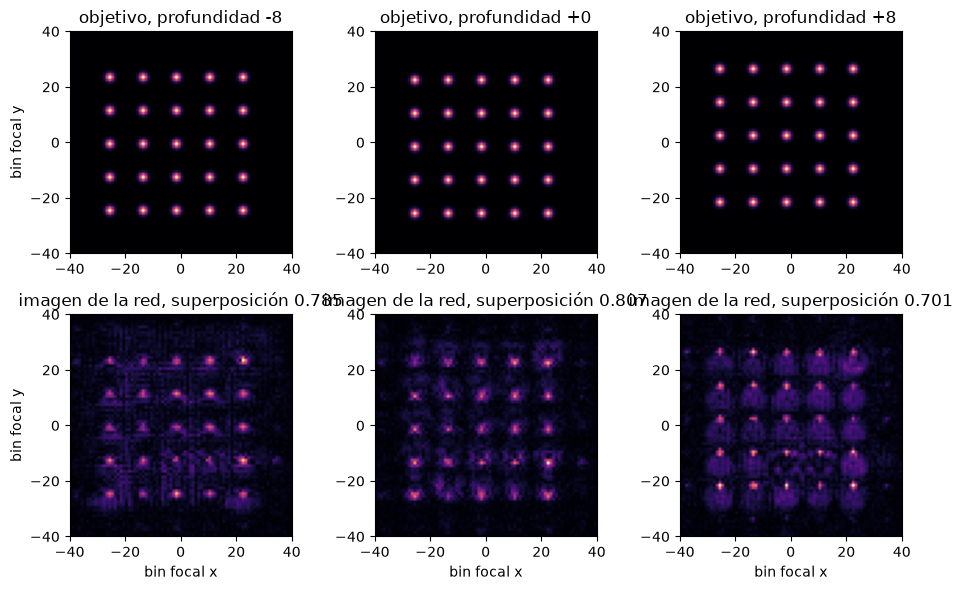

In [4]:
# el objetivo y la imagen de la red en cada profundidad para ese volumen, con la superposición de cada plano
fig, axes = plt.subplots(2, 3, figsize=(9.5, 6))
for k, z in enumerate(DEPTHS):
    axes[0, k].imshow(goals[k][24:104, 24:104], cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    axes[1, k].imshow(np.sqrt(images[k][24:104, 24:104]), cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    axes[0, k].set_title(f"objetivo, profundidad {z:+d}")
    axes[1, k].set_title(f"imagen de la red, superposición {per_plane[k]:.3f}")
    axes[1, k].set_xlabel("bin focal x")
axes[0, 0].set_ylabel("bin focal y")
axes[1, 0].set_ylabel("bin focal y")
fig.tight_layout()
plt.show()

El objetivo es una red de 25 puntos por plano, desplazada de un plano a otro; la imagen de la red lleva la red en cada profundidad, con puntos de brillo desigual, cada uno seguido por un halo, y con el plano en +8 el más borroso, que es también el de menor superposición, 0,7006. La pérdida es un único número hecho de estas tres imágenes, y una imagen puede estar mal de varias maneras a la vez: un punto tenue, uno difuminado, una bruma entre puntos. La figura no muestra cuál de ellas castiga más la pérdida. El paso siguiente pregunta si la pérdida separa una máscara que conoce el objetivo de una que no, en los 24 volúmenes, con una fase plana y una fase aleatoria como máscaras no informadas.

In [5]:
# la pérdida en 24 volúmenes nuevos para la red, una fase plana y una fase aleatoria, con la función del producto
losses = {"cgh-net": [], "fase plana": [], "fase aleatoria": []}
for kind, amps, _ in volumes:
    net = m17_cgh_net.predict(session, amps[None])
    for name, phi in zip(losses, (net, np.zeros_like(net), rng.uniform(-np.pi, np.pi, net.shape))):
        losses[name].append(1 - evaluation.plane_accuracy(amps, phi))
for name, values in losses.items():
    print(f"{name:12s} pérdida: mediana {np.median(values):.4f}, rango {min(values):.4f} a {max(values):.4f}")


cgh-net      pérdida: mediana 0.3102, rango 0.1946 a 0.3796
fase plana   pérdida: mediana 0.9999, rango 0.7737 a 1.0000
fase aleatoria pérdida: mediana 0.9829, rango 0.9483 a 0.9955


La pérdida mediana de la red es 0,3102, con un rango de 0,1946 a 0,3796, frente a 0,9999 para una fase plana y 0,9829 para una fase aleatoria; incluso la mejor de las máscaras no informadas, 0,7737 con una fase plana, queda muy por encima del peor resultado de la red. La pérdida separa los dos tipos de máscara por un margen amplio en cada volumen, de modo que lleva la información que necesita un aprendiz. El paso siguiente hace otra pregunta: ¿la fase de la red es un punto que la pérdida prefiere, o uno por el que solo pasa? La celda suma ruido de tamaño creciente, de 0 a 1,6 rad por píxel, a la fase de la red en un volumen de cada tipo y recalcula la pérdida.

In [6]:
# la pérdida alrededor de la fase de la red: ruido de tamaño creciente sumado a la fase de cuatro volúmenes
sizes = (0.0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6)
noise = np.random.default_rng(3).standard_normal((128, 128))
around = {}
for kind, amps, _ in volumes[:4]:
    net = m17_cgh_net.predict(session, amps[None])
    around[kind] = [1 - evaluation.plane_accuracy(amps, net + s * noise) for s in sizes]
    print(f"{kind:8s}", " ".join(f"{v:.4f}" for v in around[kind]))
print("tamaños de ruido (rad):", sizes)


random   0.2825 0.2833 0.2858 0.2959 0.3388 0.5227 0.8978
lattice  0.2357 0.2365 0.2387 0.2476 0.2868 0.4727 0.8888
ring     0.2933 0.2940 0.2962 0.3052 0.3447 0.5274 0.9241
mixed    0.2862 0.2870 0.2894 0.2992 0.3415 0.5230 0.8944
tamaños de ruido (rad): (0.0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.6)


Cada fila es un volumen y cada columna un tamaño de ruido, 0, 0,05, 0,1, 0,2, 0,4, 0,8 y 1,6 rad; la pérdida del volumen aleatorio va de 0,2825 a 0,2833, 0,2858, 0,2959, 0,3388, 0,5227 y 0,8978. La figura dibuja los cuatro volúmenes en un eje logarítmico simétrico para el ruido.

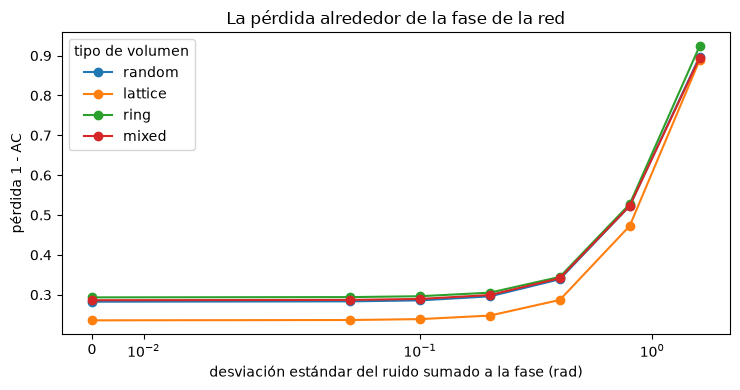

In [7]:
# las mismas cuatro curvas: la pérdida frente al tamaño del ruido sumado a la fase
fig, ax = plt.subplots(figsize=(7.5, 4))
for kind, values in around.items():
    ax.plot(sizes, values, "o-", label=kind)
ax.set_xscale("symlog", linthresh=0.05)
ax.set_xlabel("desviación estándar del ruido sumado a la fase (rad)")
ax.set_ylabel("pérdida 1 - AC")
ax.set_title("La pérdida alrededor de la fase de la red")
ax.legend(title="tipo de volumen")
fig.tight_layout()
plt.show()

Las cuatro curvas son planas para ruido menor que 0,1 rad, suben suavemente hasta 0,4 rad y luego crecen con fuerza, hasta entre 0,8888 y 0,9241 con 1,6 rad, cerca de la pérdida mediana de una máscara aleatoria, 0,9829; las curvas de los cuatro tipos tienen casi la misma forma, salvo que la de la red está más abajo. El ruido nunca bajó la pérdida, de modo que la fase de la red no está en un lugar donde un empujón al azar ayude, y la pérdida a su alrededor es un cuenco suave, que es lo que necesita un método de gradiente. La figura prueba un sorteo de ruido por volumen y solo direcciones aleatorias: no muestra que la fase sea un mínimo, porque podría existir una dirección de descenso que el ruido no encuentra. El paso siguiente mira lo que la pérdida deja fuera, las trampas mismas, y compara la red con M04, el lazo de Gerchberg-Saxton simple, corrido 30 iteraciones sobre los mismos volúmenes.

In [8]:
# lo que la pérdida no ve: la eficiencia y la uniformidad de las trampas, red frente a M04 en los mismos volúmenes
trap_view = {"cgh-net": [], "M04": []}
for kind, amps, points in volumes:
    target = evaluation.volume_target(points)
    gs = m04_gs.run(setup, target, budget=Budget(30), rng=Rng(1))
    for name, phi in (("cgh-net", m17_cgh_net.predict(session, amps[None])), ("M04", gs.phi)):
        weighted = metrics.trap_intensities(forward.point_trap_fields(phi, setup, target.traps), target.traps.weight)
        eff, uni = metrics.efficiency(weighted), metrics.uniformity(weighted)
        trap_view[name].append((eff, uni, evaluation.plane_accuracy(amps, phi)))
for name, rows in trap_view.items():
    eff, uni, acc = np.median(np.array(rows), axis=0)
    print(f"{name:8s} eficiencia mediana {eff:.3f}, uniformidad {uni:.3f}, exactitud {acc:.3f}")

cgh-net  eficiencia mediana 0.388, uniformidad 0.558, exactitud 0.690
M04      eficiencia mediana 0.745, uniformidad 0.803, exactitud 0.606


Sobre los mismos 24 volúmenes la red tiene la mayor exactitud, 0,690 frente a 0,606 de M04, y la menor eficiencia, 0,388 frente a 0,745, y la menor uniformidad, 0,558 frente a 0,803. Las dos vistas ordenan los hologramas al revés, como cabe esperar de una pérdida que contiene la primera y no las otras: la red pone poco más de un tercio de la luz en las trampas y es mejor en las imágenes, mientras el lazo clásico pone tres cuartos en las trampas y es mejor para igualarlas. Ninguna etiqueta habría dicho otra cosa, porque una pérdida sin etiquetas pide solo lo que contiene su fórmula. Es una afirmación sobre 24 volúmenes y 30 iteraciones de M04, y no dice qué haría una pérdida con otros pesos. A continuación, cómo se mueve la pérdida del lazo clásico con sus iteraciones en el volumen de red del primer paso, frente a la única pasada de la red.

In [9]:
# un lazo clásico con iteraciones: la pérdida de M04 en el volumen de red tras 1, 5, 10, 30 y 100 iteraciones
kind, amps, points = volumes[1]
target = evaluation.volume_target(points)
phi_now, done, curve = None, 0, {}
for stop in (1, 5, 10, 30, 100):
    run = m04_gs.run(setup, target, budget=Budget(stop - done), rng=Rng(1), init=phi_now)
    phi_now, done = run.phi, stop
    curve[stop] = 1 - evaluation.plane_accuracy(amps, phi_now)
    print(f"M04 tras {stop:3d} iteraciones: pérdida {curve[stop]:.4f}")
net_loss = 1 - evaluation.plane_accuracy(amps, m17_cgh_net.predict(session, amps[None]))
print(f"la red, una pasada: pérdida {net_loss:.4f}")

M04 tras   1 iteraciones: pérdida 0.3657
M04 tras   5 iteraciones: pérdida 0.3511
M04 tras  10 iteraciones: pérdida 0.3475
M04 tras  30 iteraciones: pérdida 0.3450
M04 tras 100 iteraciones: pérdida 0.3452
la red, una pasada: pérdida 0.2357


M04 obtiene una pérdida de 0,3657 tras una iteración, 0,3511 tras 5, 0,3475 tras 10, 0,3450 tras 30 y 0,3452 tras 100: se asienta cerca de 0,345 en treinta iteraciones y ahí se queda, mientras la única pasada de la red da 0,2357 en este volumen. Gerchberg-Saxton no optimiza esta pérdida, porque proyecta entre el plano focal y el SLM y conserva la fase, y en este volumen sus proyecciones se estancan por encima de lo que alcanza una pasada de la red. Ese es el valor de entrenar contra la pérdida misma, y también su límite: es un volumen y un arranque de M04, y los números propios de las trampas del paso anterior iban en sentido contrario. El registro de entrenamiento dice cuánto se le mostró a la red. La celda imprime los pasos, el lote, las semillas y los límites que el producto escribió al entrenar el grafo, cuántos volúmenes eso hace, y los dos números de paridad que guardó el paso de exportación.

In [10]:
# lo que declara el registro de entrenamiento: cuántos volúmenes vio la red y con qué semillas y límites
config = training["config"]
seen = config["steps"] * config["batch"]
parity = training["parity_wrapped_abs_diff"]
print(f"pasos {config['steps']} x lote {config['batch']} = {seen} volúmenes sorteados al vuelo")
print(f"tasa de aprendizaje {config['lr']}, semilla de datos {config['data_seed']}")
print(f"semilla de inicialización {config['init_seed']}, tope de tiempo {config['max_hours']} h")
print(f"operadores ONNX en el grafo: {len(training['operators'])}")
print("paridad en las intensidades de plano, mayor diferencia relativa:")
print(f"    {training['parity_intensity_rel_max']:.2e}")
print(f"fracción de píxeles de fase que difieren en más de 1e-5: {parity['share_above_1e-5']:.3f}")

pasos 16000 x lote 32 = 512000 volúmenes sorteados al vuelo
tasa de aprendizaje 0.001, semilla de datos 20261103
semilla de inicialización 13, tope de tiempo 2.2 h
operadores ONNX en el grafo: 19
paridad en las intensidades de plano, mayor diferencia relativa:
    8.42e-06
fracción de píxeles de fase que difieren en más de 1e-5: 0.280


La red vio 16000 pasos de 32 volúmenes, 512000 volúmenes, cada uno sorteado al vuelo desde el generador con semilla, con semilla de datos 20261103 y semilla de inicialización 13: no se guardó ningún conjunto de datos, y los datos de la corrida pueden volver a sortearse desde su semilla. El grafo exportado tiene 19 tipos de operador. Su paridad con el marco de entrenamiento se declara sobre las intensidades de plano, con una diferencia relativa máxima de 8,42e-06, y no sobre la fase, porque 0,280 de los píxeles de fase difieren en más de 1e-5 tras envolver: la fase está mal condicionada donde el campo del SLM es casi nulo, y lo que debe coincidir es la luz, que coincide. Este es el registro guardado de una corrida, y el notebook no repitió la corrida. A continuación, la evidencia con datos reservados: 162 volúmenes escritos antes del entrenamiento con otras semillas, en los que el producto comparó la red sola con el GS volumétrico (M19) con el mismo tiempo de reloj. La celda lee las exactitudes por volumen.

In [11]:
# el registro con datos reservados: exactitud de la red sola y del GS volumétrico con igual tiempo de reloj
rows = detail["rows"]
net = np.array([r["ac_net_alone"] for r in rows])
m19 = np.array([r["ac_m19_matched"] for r in rows])
ratio = net / m19
print(f"volúmenes {len(rows)}, exactitud mediana: red {np.median(net):.4f}, M19 {np.median(m19):.4f}")
print(f"razón red / M19: mediana {np.median(ratio):.4f}, menor {ratio.min():.4f}, mayor {ratio.max():.4f}")
print(f"fracción de volúmenes donde la red supera a M19: {np.mean(ratio > 1):.3f}")
print(f"iteraciones que M19 alcanzó en el tiempo de reloj: mediana {detail['m19_matched_iterations_median']:.0f}")
print(f"tiempo de reloj de M19 {detail['wall_clock_budget_ms']:.0f} ms")
print(f"pasada de la red: mediana {detail['network_ms_median']:.0f} ms")

volúmenes 162, exactitud mediana: red 0.6869, M19 0.5997
razón red / M19: mediana 1.1400, menor 1.0654, mayor 1.2603
fracción de volúmenes donde la red supera a M19: 1.000
iteraciones que M19 alcanzó en el tiempo de reloj: mediana 37
tiempo de reloj de M19 7355 ms
pasada de la red: mediana 35 ms


Sobre los 162 volúmenes reservados la exactitud mediana es 0,6869 para la red y 0,5997 para M19, la razón mediana es 1,1400, la razón menor es 1,0654 y la red supera a M19 en todos los volúmenes, una fracción de 1,000. M19 tuvo un tiempo de reloj de 7355 ms que le dio una mediana de 37 iteraciones, y la red sola ocupó una mediana de 35 ms. A continuación, cómo depende la razón del tipo de volumen y de la fracción del tiempo de reloj que se da al lazo.

In [12]:
# el mismo registro por tipo de volumen y según la fracción del tiempo de reloj dada al lazo
by_kind = {}
for i, r in enumerate(rows):
    by_kind.setdefault(r["volume"].split("/")[1], []).append(i)
for kind, where in sorted(by_kind.items()):
    part = ratio[where]
    print(f"{kind:8s} n = {part.size:3d}  razón: mediana {np.median(part):.4f}, menor {part.min():.4f}")
for label, point in detail["budget_curve"].items():
    median = point["ratio_hybrid_over_m19"]["median"]
    print(f"presupuesto {label}: híbrido/M19, mediana {median:.4f}, fracción sobre 1 {point['share_above_1']:.2f}")
accuracy = detail["ac_median"]
print("exactitud mediana, híbrido y red sola:", round(accuracy["ac_hybrid"], 4), round(accuracy["ac_net_alone"], 4))
print("mayor diferencia por volumen, híbrido contra red sola:",
      max(abs(r["ac_hybrid"] - r["ac_net_alone"]) for r in rows))

bench    n =   2  razón: mediana 1.1267, menor 1.0654
lattice  n =  40  razón: mediana 1.1623, menor 1.0892
mixed    n =  40  razón: mediana 1.1183, menor 1.0814
random   n =  40  razón: mediana 1.1469, menor 1.0975
ring     n =  40  razón: mediana 1.1004, menor 1.0764
presupuesto 2427 ms: híbrido/M19, mediana 1.1494, fracción sobre 1 1.00
presupuesto 4413 ms: híbrido/M19, mediana 1.1479, fracción sobre 1 1.00
exactitud mediana, híbrido y red sola: 0.6869 0.6869
mayor diferencia por volumen, híbrido contra red sola: 0.0


La razón es 1,1623 para redes, 1,1469 para conjuntos aleatorios, 1,1183 para volúmenes mixtos y 1,1004 para anillos, con 1,1267 para las dos geometrías de referencia, y el menor valor de cada grupo está sobre 1,06. Dando al lazo solo 33 por ciento o 60 por ciento del tiempo de reloj el híbrido mantiene una razón mediana de 1,1494 y 1,1479, otra vez en cada uno de los 54 volúmenes de la curva de presupuesto; y la exactitud mediana del híbrido, 0,6869, es la misma que la de la red sola, 0,6869. La figura grafica la red contra M19 para cada volumen, con la recta de igual exactitud, y las razones por tipo.

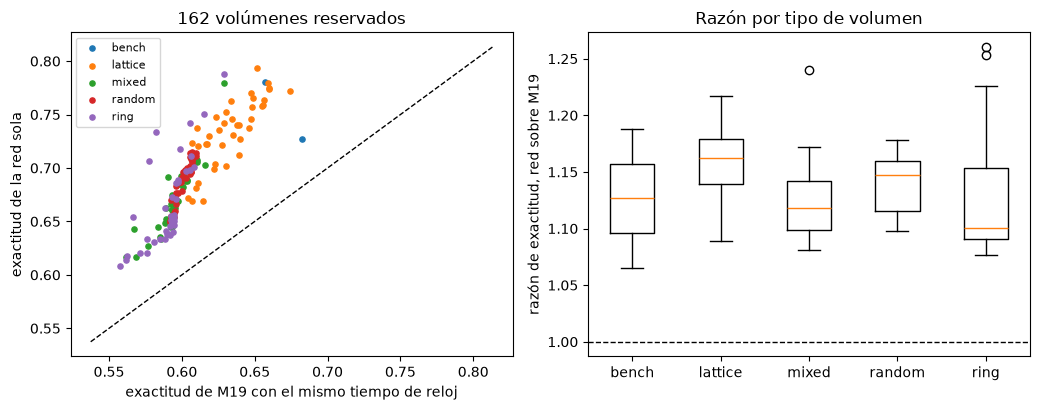

In [13]:
# izquierda: exactitud de la red frente a la de M19, un punto por volumen; derecha: la razón por tipo
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.2))
for kind, where in sorted(by_kind.items()):
    left.scatter(m19[where], net[where], s=14, label=kind)
low, high = min(m19.min(), net.min()) - 0.02, max(m19.max(), net.max()) + 0.02
left.plot([low, high], [low, high], "k--", lw=1)
left.set_xlabel("exactitud de M19 con el mismo tiempo de reloj")
left.set_ylabel("exactitud de la red sola")
left.set_title("162 volúmenes reservados")
left.legend(fontsize=8)
right.boxplot([ratio[where] for _, where in sorted(by_kind.items())], tick_labels=sorted(by_kind))
right.axhline(1.0, color="k", ls="--", lw=1)
right.set_ylabel("razón de exactitud, red sobre M19")
right.set_title("Razón por tipo de volumen")
fig.tight_layout()
plt.show()

Cada punto del panel izquierdo queda sobre la diagonal y los puntos suben juntos: los volúmenes que son más fáciles para M19 son más fáciles para la red, lo que sugiere que el volumen lleva buena parte de la dificultad. A la derecha las cajas de los cinco grupos quedan sobre 1,0, y los anillos tienen el bigote más largo, con dos valores atípicos cerca de 1,25. Con el tiempo de reloj completo el híbrido es igual a la red sola en cada uno de los 162 volúmenes (la línea de arriba), y en los dos presupuestos más cortos el registro guarda solo su razón con M19; así que con el presupuesto completo el refinamiento que pagó el tiempo de reloj nunca cambió la respuesta en el registro. La figura es el registro del producto y no una medición nueva, y no dice cómo se comporta la red fuera de las familias de entrenamiento, ya que los volúmenes reservados vienen del mismo generador y de las geometrías de referencia; tampoco dice nada de los números propios de las trampas, que el paso anterior mostró más bajos. La última celda es la única comprobación de reproducción del notebook.

In [14]:
# la única comprobación de reproducción: el archivo publicado es el que describen la ficha y el registro
digest = hashlib.sha256((ROOT / "models" / "cgh-net.onnx").read_bytes()).hexdigest()
print("el sha256 del archivo es igual al de la ficha:", digest == card["sha256"])
listed = training["heldout_sha256"] in card["held_out"]["en"]
print("el hash de los datos reservados del registro aparece en la ficha:", listed)

el sha256 del archivo es igual al de la ficha: True
el hash de los datos reservados del registro aparece en la ficha: True


## Resultados

**Respuesta:** La red aprende sin hologramas de ejemplo porque su pérdida, uno menos la exactitud de la luz que hace su propia máscara en tres profundidades, solo necesita el objetivo y el modelo directo: en 24 volúmenes nuevos obtiene una pérdida mediana de 0,3102 frente a 0,9999 de una fase plana y 0,9829 de una fase aleatoria, y alrededor de la fase de la red un ruido de 0,2 rad sube la pérdida solo de 0,2825 a 0,2959 en un volumen y 1,6 rad la lleva a 0,8978, un cuenco suave. El costo de pedir solo traslape se ve en las trampas: la eficiencia mediana de la red es 0,388 frente a 0,745 de M04, y su uniformidad 0,558 frente a 0,803, aunque su exactitud es mayor, 0,690 frente a 0,606. El registro de 162 volúmenes reservados muestra a la red sobre el GS volumétrico en todos ellos, con razón mediana de 1,1400 y menor de 1,0654, y un híbrido que nunca mejora a la red sola, 0,6869 en ambos. El registro no muestra el comportamiento fuera de las familias de entrenamiento, no muestra el entrenamiento mismo, que aquí no se ejecutó, y compara la red con una línea base en un tiempo de reloj en una máquina.

## Resumen

Una pérdida sin etiquetas convierte la óptica en maestra: la máscara de la propia red se propaga a tres profundidades y se compara con el objetivo, y bastaron 512000 objetivos sorteados por un generador con semilla para dejar la pérdida baja y suave alrededor de la fase aprendida. Lo que contiene la pérdida es lo que la red optimiza, de modo que gana en traslape de imágenes, 1,1400 veces el GS volumétrico en la mediana sobre 162 volúmenes reservados, y pierde en eficiencia y uniformidad de las trampas. El notebook siguiente corre la red contra el lazo volumétrico clásico en un caso del producto y pregunta con cuál de las dos vistas debe juzgarse un arreglo de trampas.

## Referencias

- Eybposh, Caira, Atisa, Chakravarthula and Pégard, "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- onnxruntime 1,31.1 (MIT), https://pypi.org/pypi/onnxruntime/json and https://pypi.org/project/onnxruntime/.